# Predictor performance

Evaluate the ensemble of three predictors against experimentally measured scores on each test set.

In [1]:
# Evaluate the ensemble of predictors against experimentally measured scores for the three datasets.
import pandas as pd
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

## Load predictor outputs

In [2]:
# Load the data.
plm_res = "...\\pLM-bVAE\\reproduction_paper\\outputs\\"

# peptide
pep_parrot_model1 = pd.read_csv(plm_res +'parrot\\parrot_models\\peptide\\model1\\network_predictions.tsv', sep=" ", header=None, names=["id", "seq", "bb_score"])
pep_parrot_model2 = pd.read_csv(plm_res +'parrot\\parrot_models\\peptide\\model2\\network_predictions.tsv', sep=" ", header=None, names=["id", "seq", "bb_score"])
pep_parrot_model3 = pd.read_csv(plm_res +'parrot\\parrot_models\\peptide\\model3\\network_predictions.tsv', sep=" ", header=None, names=["id", "seq", "bb_score"])
# Calculate the mean predictor score for the peptide data.
pep_parrot_model1['bb_score_avg'] = (pep_parrot_model1['bb_score'] + pep_parrot_model2['bb_score'] + pep_parrot_model3['bb_score']) / 3

# cdrh3
cdrh3_parrot_model1 = pd.read_csv(plm_res +'parrot\\parrot_models\\cdrh3\\model1\\network_predictions.tsv', sep=" ", header=None, names=["id", "seq", "bb_score"])
cdrh3_parrot_model2 = pd.read_csv(plm_res +'parrot\\parrot_models\\cdrh3\\model2\\network_predictions.tsv', sep=" ", header=None, names=["id", "seq", "bb_score"])
cdrh3_parrot_model3 = pd.read_csv(plm_res +'parrot\\parrot_models\\cdrh3\\model3\\network_predictions.tsv', sep=" ", header=None, names=["id", "seq", "bb_score"])
# Calculate the mean predictor score for the CDRH3 data.
cdrh3_parrot_model1['bb_score_avg'] = (cdrh3_parrot_model1['bb_score'] + cdrh3_parrot_model2['bb_score'] + cdrh3_parrot_model3['bb_score']) / 3

# aav
aav_parrot_model1 = pd.read_csv(plm_res +'parrot\\parrot_models\\aav\\model1\\network_predictions.tsv', sep=" ", header=None, names=["id", "seq", "bb_score"])
aav_parrot_model2 = pd.read_csv(plm_res +'parrot\\parrot_models\\aav\\model2\\network_predictions.tsv', sep=" ", header=None, names=["id", "seq", "bb_score"])
aav_parrot_model3 = pd.read_csv(plm_res +'parrot\\parrot_models\\aav\\model3\\network_predictions.tsv', sep=" ", header=None, names=["id", "seq", "bb_score"])
# Calculate the mean predictor score for the AAV data.
aav_parrot_model1['bb_score_avg'] = (aav_parrot_model1['bb_score'] + aav_parrot_model2['bb_score'] + aav_parrot_model3['bb_score']) / 3

In [3]:
pep_parrot_model1

,id,seq,bb_score,bb_score_avg
0,10944_TRUE,VMNNLSELT,7.638293,7.638293
1,10944_PRED,VMNNLSELT,9.224875,8.264801
2,10945_TRUE,KLLARFLFE,9.903487,9.903487
3,10945_PRED,KLLARFLFE,10.394151,8.817240
4,10946_TRUE,QLAFTYCQV,6.340359,6.340359
...,...,...,...,...
2427,12157_PRED,ITTMDGDKL,10.335401,10.153022
2428,12158_TRUE,GLQGIYVLV,1.098612,1.098612
2429,12158_PRED,GLQGIYVLV,3.820442,4.226787
2430,12159_TRUE,THFQRKRRV,9.903487,9.903487


In [4]:
aav_parrot_model1

,id,seq,bb_score,bb_score_avg
0,15068_TRUE,TNNAEIATTNPVAYERWGSVACITNWQGGQGQNEG,-2.031522,-2.031522
1,15068_PRED,TNNAEIATTNPVAYERWGSVACITNWQGGQGQNEG,-3.266234,-3.666507
2,15069_TRUE,DEHEIRTTNPVATETYGSVSTNLQRGGERG,1.785573,1.785573
3,15069_PRED,DEHEIRTTNPVATETYGSVSTNLQRGGERG,0.931792,0.316682
4,15070_TRUE,DEEEIATTNPVATEQYGSVSTNLQGDGNMQE,1.121449,1.121449
...,...,...,...,...
3345,16740_PRED,DEAEIATTNPVATEQYGIVSTNLQAGGNQ,0.828861,0.882955
3346,16741_TRUE,DEHEIRTTNPVATEQYGSVSTTGPEQGLGNMGQ,1.629093,1.629093
3347,16741_PRED,DEHEIRTTNPVATEQYGSVSTTGPEQGLGNMGQ,1.214713,1.181973
3348,16742_TRUE,DEHEEEIATTNPVATEQYGSVCSTNDGNDAGGENKG,-6.721393,-6.721393


## Match measured and predicted scores

In [5]:
# peptide
# Copy measured scores from rows whose IDs contain TRUE into true_score.
pep_parrot_model = pep_parrot_model1.copy()
pep_parrot_model['true_score'] = pep_parrot_model.apply(lambda row: row['bb_score'] if 'TRUE' in row['id'] else np.nan, axis=1)
# Copy measured scores to rows sharing the first five ID characters.
pep_parrot_model['true_score'] = pep_parrot_model.apply(lambda row: row['true_score'] if pd.notna(row['true_score']) else pep_parrot_model[pep_parrot_model['id'].str.startswith(row['id'][:5])]['true_score'].values[0], axis=1)
# Remove the rows whose IDs contain TRUE.
pep_parrot_model = pep_parrot_model[~pep_parrot_model['id'].str.contains('TRUE')].reset_index(drop=True)
# Remove the bb_score column.
pep_parrot_model = pep_parrot_model.drop(columns=['bb_score'])

# cdrh3
# Copy measured scores from rows whose IDs contain TRUE into true_score.
cdrh3_parrot_model = cdrh3_parrot_model1.copy()
cdrh3_parrot_model['true_score'] = cdrh3_parrot_model.apply(lambda row: row['bb_score'] if 'TRUE' in row['id'] else np.nan, axis=1)
# Copy measured scores to rows sharing the first four ID characters.
cdrh3_parrot_model['true_score'] = cdrh3_parrot_model.apply(lambda row: row['true_score'] if pd.notna(row['true_score']) else cdrh3_parrot_model[cdrh3_parrot_model['id'].str.startswith(row['id'][:4])]['true_score'].values[0], axis=1)
# Remove the rows whose IDs contain TRUE.
cdrh3_parrot_model = cdrh3_parrot_model[~cdrh3_parrot_model['id'].str.contains('TRUE')].reset_index(drop=True)
# Remove the bb_score column.
cdrh3_parrot_model = cdrh3_parrot_model.drop(columns=['bb_score'])

# aav
# Copy measured scores from rows whose IDs contain TRUE into true_score.
aav_parrot_model = aav_parrot_model1.copy()
aav_parrot_model['true_score'] = aav_parrot_model.apply(lambda row: row['bb_score'] if 'TRUE' in row['id'] else np.nan, axis=1)
# Copy measured scores to rows sharing the first five ID characters.
aav_parrot_model['true_score'] = aav_parrot_model.apply(lambda row: row['true_score'] if pd.notna(row['true_score']) else aav_parrot_model[aav_parrot_model['id'].str.startswith(row['id'][:5])]['true_score'].values[0], axis=1)
# Remove the rows whose IDs contain TRUE.
aav_parrot_model = aav_parrot_model[~aav_parrot_model['id'].str.contains('TRUE')].reset_index(drop=True)
# Remove the bb_score column.
aav_parrot_model = aav_parrot_model.drop(columns=['bb_score'])

## Compare predictions with measurements

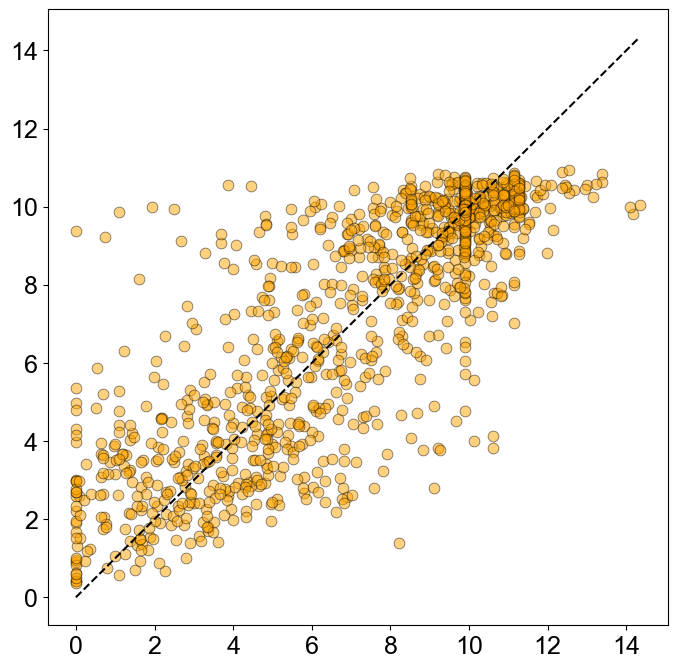

In [6]:
# Plot measured versus mean predicted scores for peptides.
plt.figure(figsize=(8, 8))
sns.scatterplot(data=pep_parrot_model, x='true_score', y='bb_score_avg', color='orange', marker='o', s=60, alpha=0.5, edgecolor='black')
# plt.xlabel('True Score')
# plt.ylabel('Average Predicted Score')
# plt.title('Peptide: True Score vs Average Predicted Score')
# Add the diagonal reference line.
plt.plot([pep_parrot_model['true_score'].min(), pep_parrot_model['true_score'].max()], [pep_parrot_model['true_score'].min(), pep_parrot_model['true_score'].max()], color='black', linestyle='--')

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.xlabel('')
plt.ylabel('')
plt.show()

In [7]:
# Calculate Pearson and Spearman correlations.
from scipy.stats import pearsonr, spearmanr
pearson_corr, pearson_p = pearsonr(pep_parrot_model['true_score'], pep_parrot_model['bb_score_avg'])
spearman_corr, spearman_p = spearmanr(pep_parrot_model['true_score'], pep_parrot_model['bb_score_avg'])
print(f"Peptide - Pearson correlation: {pearson_corr:.4f} (p-value: {pearson_p:.4e})")
print(f"Peptide - Spearman correlation: {spearman_corr:.4f} (p-value: {spearman_p:.4e})")

Peptide - Pearson correlation: 0.8380 (p-value: 1.2253e-321)
Peptide - Spearman correlation: 0.8058 (p-value: 1.5879e-278)


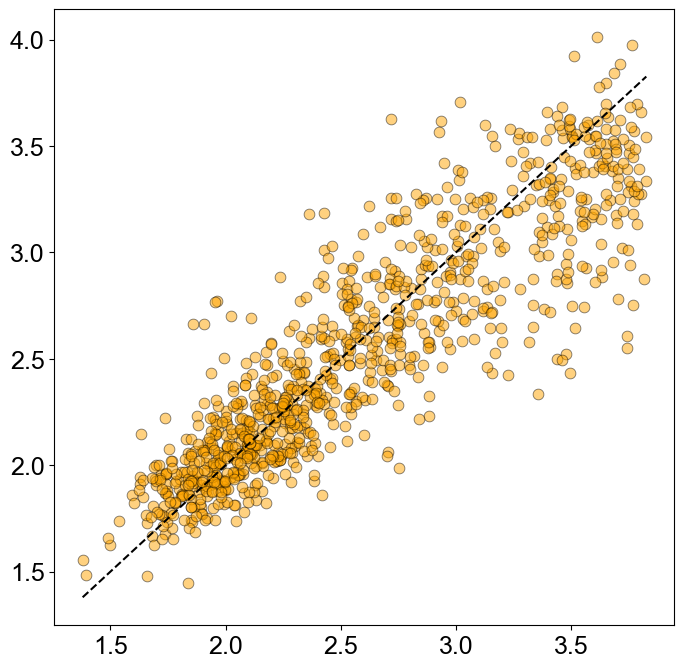

In [8]:
# Plot measured versus mean predicted scores for CDRH3 variants.
plt.figure(figsize=(8, 8))
sns.scatterplot(data=cdrh3_parrot_model, x='true_score', y='bb_score_avg', color='orange', marker='o', s=60, alpha=0.5, edgecolor='black')
# plt.xlabel('True Score')
# plt.ylabel('Average Predicted Score')
# plt.title('CDRH3: True Score vs Average Predicted Score')
# Add the diagonal reference line.
plt.plot([cdrh3_parrot_model['true_score'].min(), cdrh3_parrot_model['true_score'].max()], [cdrh3_parrot_model['true_score'].min(), cdrh3_parrot_model['true_score'].max()], color='black', linestyle='--')

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.xlabel('')
plt.ylabel('')
plt.show()

In [9]:
# Calculate Pearson and Spearman correlations.
from scipy.stats import pearsonr, spearmanr
pearson_corr, pearson_p = pearsonr(cdrh3_parrot_model['true_score'], cdrh3_parrot_model['bb_score_avg'])
spearman_corr, spearman_p = spearmanr(cdrh3_parrot_model['true_score'], cdrh3_parrot_model['bb_score_avg'])
print(f"CDRH3 - Pearson correlation: {pearson_corr:.4f} (p-value: {pearson_p:.4e})")
print(f"CDRH3 - Spearman correlation: {spearman_corr:.4f} (p-value: {spearman_p:.4e})")

CDRH3 - Pearson correlation: 0.8901 (p-value: 0.0000e+00)
CDRH3 - Spearman correlation: 0.8987 (p-value: 0.0000e+00)


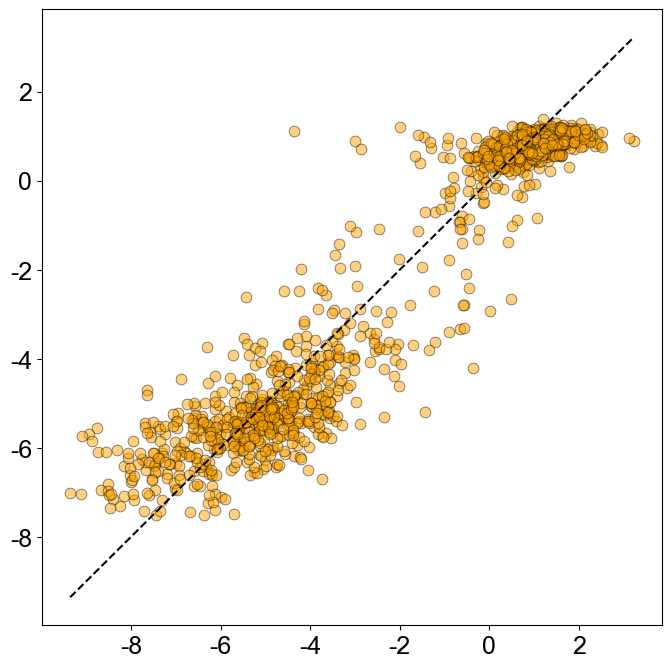

In [10]:
# Plot measured versus mean predicted scores for AAV variants.
plt.figure(figsize=(8, 8))
sns.scatterplot(data=aav_parrot_model, x='true_score', y='bb_score_avg', color='orange', marker='o', s=60, alpha=0.5, edgecolor='black')
# plt.xlabel('True Score')
# plt.ylabel('Average Predicted Score')
# plt.title('AAV: True Score vs Average Predicted Score')
# Add the diagonal reference line.
plt.plot([aav_parrot_model['true_score'].min(), aav_parrot_model['true_score'].max()], [aav_parrot_model['true_score'].min(), aav_parrot_model['true_score'].max()], color='black', linestyle='--')

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.xlabel('')
plt.ylabel('')
plt.show()

In [11]:
# Calculate Pearson and Spearman correlations.
from scipy.stats import pearsonr, spearmanr
pearson_corr, pearson_p = pearsonr(aav_parrot_model['true_score'], aav_parrot_model['bb_score_avg'])
spearman_corr, spearman_p = spearmanr(aav_parrot_model['true_score'], aav_parrot_model['bb_score_avg'])
print(f"AAV - Pearson correlation: {pearson_corr:.4f} (p-value: {pearson_p:.4e})")
print(f"AAV - Spearman correlation: {spearman_corr:.4f} (p-value: {spearman_p:.4e})")

AAV - Pearson correlation: 0.9637 (p-value: 0.0000e+00)
AAV - Spearman correlation: 0.8768 (p-value: 0.0000e+00)
